      电影名      年份        上映时间        类型   时长  评分  语言         导演       作者  \
0  肖申克的救赎  1994.0  1994-09-23     剧情,犯罪  142  87  英语   弗兰克·德拉邦特    斯蒂芬·金   
1      教父  1972.0  1972-03-24     剧情,犯罪  175  87  英语   弗朗西斯·科波拉   马里奥·普佐   
2     教父2  1974.0  1974-12-20     剧情,犯罪  200  86  英语   弗朗西斯·科波拉   马里奥·普佐   
3  辛德勒的名单  1993.0  2019-04-06  剧情,历史,战争  195  86  英语  史蒂文·斯皮尔伯格  托马斯·肯尼利   
4    十二怒汉  1957.0  1957-04-10        剧情   96  86  英语    雷金纳德·罗斯  西德尼·卢梅特   

                                         宣传语  \
0                        恐惧会将你囚禁，希望则能让你获得自由。   
1                 An offer you can't refuse.   
2  The rise and fall of the Corleone empire.   
3                        谁拯救了一条生命，谁就拯救了整个世界。   
4                                  命悬其手，死视其意   

                                                  简介  
0  安迪·杜佛兰被错判谋杀妻子及其情人，在缅因州肖申克服刑，判处两项无期徒刑接连执行。影片背景设...  
1  40年代的美国，“教父”维托·唐·柯里昂是黑手党柯里昂家族的首领，带领家族从事非法的勾当，但...  
2  作为《教父》的续篇，影片延续了科莱昂家族两代权力交替的史诗。科波拉在第二部分中讲述了两条故事...  
3  史蒂文·斯皮尔伯格的史诗剧情片，讲述了德国商人奥斯卡·辛德勒震

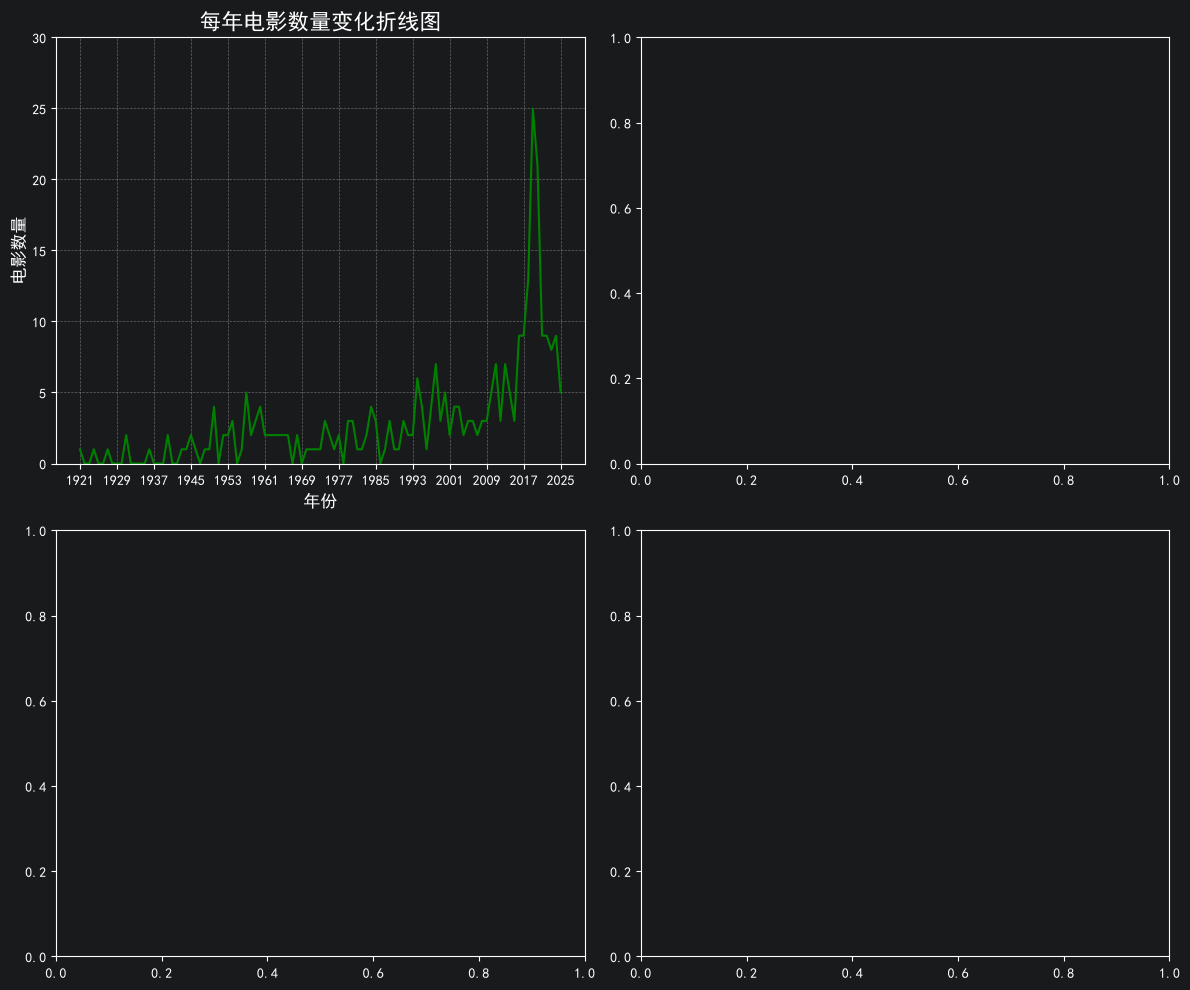

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 配置中文显示，使用黑体（SimHei），并解决负号显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 创建 2×2 子图画布
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10), dpi=100)

# 获取 4 个子图对象
ax1, ax2 = axes[0]      # 第一行的左、右两个子图
ax3, ax4 = axes[1]      # 第二行的左、右两个子图

# 加载 movies.csv 数据（文件位于本章的 data 文件夹下）
movies = pd.read_csv("data/movies.csv")


# ============ 需求 1：读取并确认数据 ============
# 明确按"年份"列统计每年上映电影数量
print(movies.head())
print(movies.columns.tolist())

# ============ 需求 2：检查缺失值 ============
print(movies.isnull())            # 查看每个单元格的空值
print(movies.isnull().sum())      # 统计每列缺失值数量 —— 可发现"年份"列有缺失

# ============ 需求 3：处理"年份"列缺失值（用"上映时间"前4位补充） ============
# 不删行，截取"上映时间"前 4 个字符作为年份，转成数值后填充"年份"的空缺
year_from_date = pd.to_numeric(
    movies["上映时间"].astype(str).str[:4],
    errors="coerce"
)
movies["年份"] = movies["年份"].fillna(year_from_date)
# 验证填充结果：年份列应不再有缺失值
print("填充后年份缺失数量:", movies["年份"].isnull().sum())

# ============ 需求 4：检查异常值（小于 0 或大于 3000） ============
abnormal = movies[(movies["年份"] < 0) | (movies["年份"] > 3000)]
print("异常年份记录数:", len(abnormal))
# 若无异常则无需额外处理

# ============ 需求 5：按年份分组统计电影数量 ============
# 统一转为整数年份，方便后续作图与索引
movies["年份"] = movies["年份"].astype(int)
year_counts = movies.groupby("年份")["电影名"].count()   # 以年份为索引、数量为值的 Series
print(year_counts)

# ============ 需求 6：组装 X 轴（连续年份，避免断续） ============
min_year = year_counts.index.min()
max_year = year_counts.index.max()
x_years = list(range(min_year, max_year + 1))

# ============ 需求 7：组装 Y 轴（每年数量，缺失年份补 0） ============
y_counts = [year_counts.get(year, 0) for year in x_years]

# ============ 需求 8 & 9：绘制折线图并美化（在第一个子图 axis1 = ax1） ============
ax1.plot(x_years, y_counts, color="green")
ax1.set_title("每年电影数量变化折线图", fontsize=16)
ax1.set_xlabel("年份", fontsize=12)
ax1.set_ylabel("电影数量", fontsize=12)

# ============ 需求 10：设置坐标轴刻度 ============
# X 轴每隔 8 年一个刻度，避免年份全部显示过于拥挤
ax1.set_xticks(range(min_year, max_year + 1, 8))
# Y 轴范围 0~30，刻度间隔为 5
ax1.set_ylim(0, 30)
ax1.set_yticks(range(0, 31, 5))

# ============ 需求 11：添加网格线（虚线 + 透明度） ============
ax1.grid(True, linestyle="--", alpha=0.5)

# ============ 需求 12：查看最终效果 ============
plt.tight_layout()
plt.show()